In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

print(Path.cwd())
print(Path("nips3_builder.py").exists())
from nisp3_mini_model_builders import *
from nisp3_mini_mc import MonteCarlo2DXY

import secrets

d:\codex-vscode-projects\Monte_Carlo_skyrmions_improved-main\NiSP3_test
True


In [2]:
# lattice size
L = 30
Nx = round(1.7*L)
if Nx % 2 == 1:
    Nx += 1
Ny = L

nisp3_lattice = build_nisp3_lattice(Nx, Ny, geometry="rectangular")

# Hamiltonian parameters
J1 = -3.8
J2 = 0.2
J3 = 13.8
K2 = 0.0
K6 = 0

mini_ham = build_nisp3_mini_model(J1=J1, J2iso=J2, J3=J3, K6=K6)

In [3]:
seed = secrets.randbits(128)
current_rng = np.random.default_rng(seed=seed)
nisp3_mc = MonteCarlo2DXY(lattice=nisp3_lattice, spin_model=mini_ham, seed=seed)

In [4]:
# Plotting helpers and common appearance.
from plotting_mc import PLOT_CONFIG, plot_spin_config, plot_spin_angles, plot_curves
plt.rcParams.update(PLOT_CONFIG)

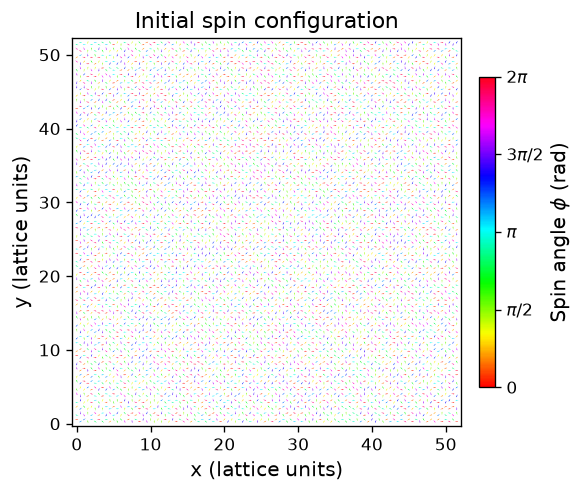

In [5]:
plot_spin_config(nisp3_mc.spin_config, nisp3_lattice, 
                 title="Initial spin configuration",figsize=(6, 4))
plt.show()

### temperatures from HIGH to LOW for annealing

In [6]:
from nisp3_mc_protocols import set_temperature_schedule

In [7]:
# set uptemperatures
TK_init_list = [200, 150, 75]
TK_final_list = [150, 75, 1]
cooling_method_list = ["linear", "geometric", "geometric"]
cooling_rate_list = [10, 0.95, 0.8]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)


In [8]:
meV_per_K = 0.08617333262
num_eq_sweeps = 15000
num_meas_sweeps = 5000
meas_per_every = 5
converg_per_every = 10


### create folder

In [9]:
from nisp3_mc_output import create_run_folder, save_temperature_results, save_neel_curve

In [10]:
mc_parameters={
    # lattice parameters
    "Nx": Nx,
    "Ny": Ny,
    "Ns": 4,
    "geometry": "rectangular",
    # model parameters
    "exchange": (J1,J2,J3),
    "in-plane anisotropy": (K2,K6),
    # Monte Carlo parameters
    "seed": seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    # "temperatures_in_K": TK_list,
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nisp3_simulation_results", parameters=mc_parameters)

### mc sweep

In [11]:
from nisp3_mc_protocols import run_mc_annealing

results = run_mc_annealing(
    nisp3_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps,
    num_meas_sweeps=num_meas_sweeps,
    converg_per_every=converg_per_every,
    meas_per_every=meas_per_every,
)

measured_temperatures_K = results["temperatures_K"]
neel_norm_of_mean_list = results["neel_norm_of_mean"]
neel_samples_by_temperature = results["neel_samples_by_temperature"]
neel_squared_temperature_list = results["neel_squared_temperature_list"]


T = 200.00 K, E = -55634.588918 meV
T = 194.44 K, E = -56700.567644 meV
T = 188.89 K, E = -60889.630554 meV
T = 183.33 K, E = -59812.749834 meV
T = 177.78 K, E = -65381.532976 meV
T = 172.22 K, E = -66993.053543 meV
T = 166.67 K, E = -68776.381462 meV
T = 161.11 K, E = -72714.484091 meV
T = 155.56 K, E = -74285.681169 meV
T = 150.00 K, E = -77027.507051 meV
T = 150.00 K, E = -76687.604367 meV
T = 142.50 K, E = -80906.715300 meV
T = 135.38 K, E = -88955.868905 meV
T = 128.61 K, E = -96148.651472 meV
T = 122.18 K, E = -100132.388467 meV
T = 116.07 K, E = -103227.367671 meV
T = 110.26 K, E = -106525.833550 meV
T = 104.75 K, E = -107468.005268 meV
T = 99.51 K, E = -111520.933957 meV
T = 94.54 K, E = -112942.966922 meV
T = 89.81 K, E = -114525.660043 meV
T = 85.32 K, E = -117055.151744 meV
T = 81.05 K, E = -117883.301640 meV
T = 77.00 K, E = -119416.820402 meV
T = 75.00 K, E = -120256.879187 meV
T = 60.00 K, E = -124958.852851 meV
T = 48.00 K, E = -128813.729742 meV
T = 38.40 K, E = -131298

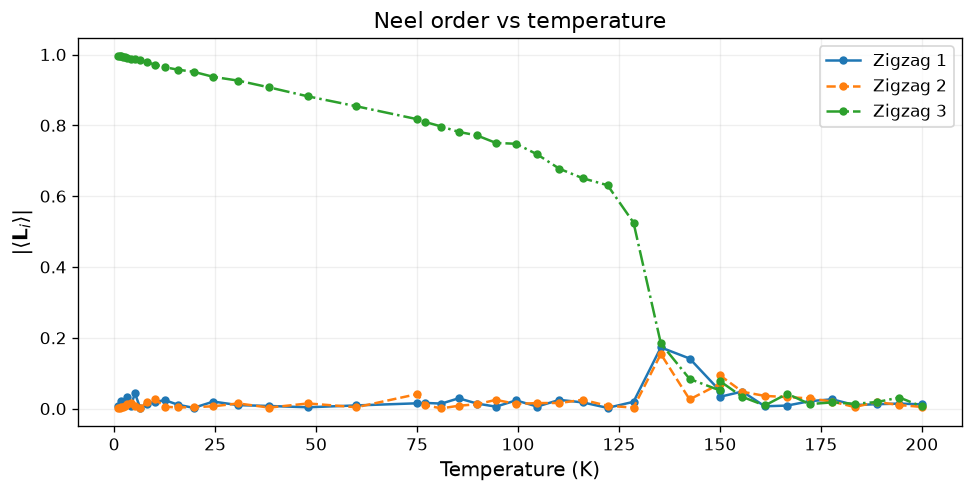

In [12]:
# Results already computed in the temperature loop.
temperatures_K = np.asarray(measured_temperatures_K)
neel_norm_of_mean = np.asarray(neel_norm_of_mean_list)

fig, ax, _ = plot_curves(
    temperatures_K, neel_norm_of_mean.T,  # (3 curves, number of temperatures)
    xlabel="Temperature (K)",
    ylabel1=r"$|\langle \mathbf{L}_i \rangle|$",
    label1=["Zigzag 1", "Zigzag 2", "Zigzag 3"],
    colors=(["tab:blue", "tab:orange", "tab:green"], "firebrick"),
    title="Neel order vs temperature",
)

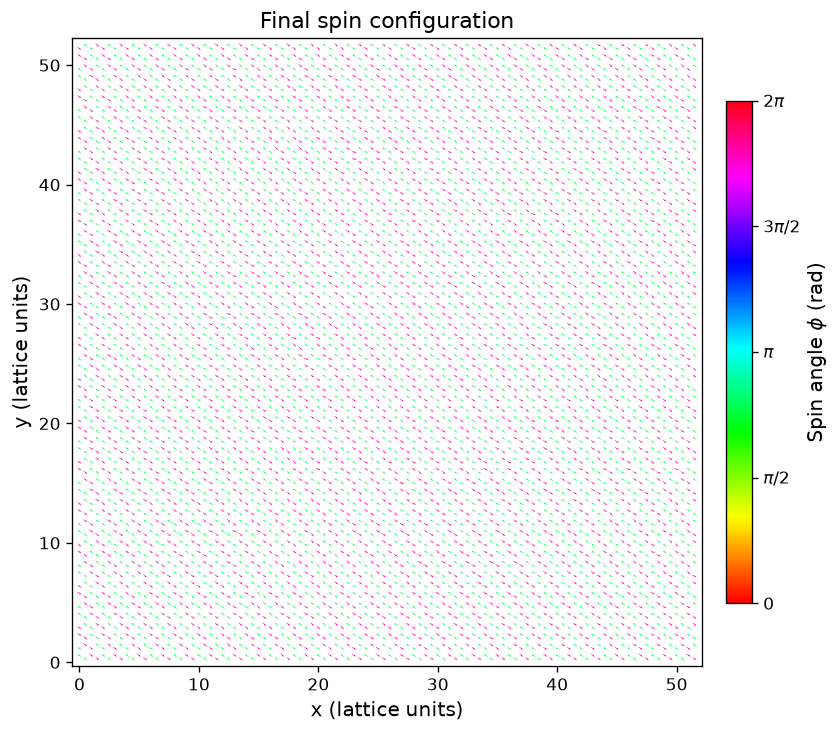

In [13]:
# Final spin configuration after the MC temperature loop.
from plotting_mc import plot_spin_config

plot_spin_config(
    nisp3_mc.spin_config,
    nisp3_mc.lat,
    title="Final spin configuration",
    figsize=(8, 6),
)
plt.show()
